# 03 - What can a shadow actually tell us about a depth map?

Two things came out of notebook 02:

1. LiDAR is a poor "oracle" for shadows. Most shadows on the road come from tree
   canopies and house fronts above the LiDAR's vertical field of view, so LiDAR geometry
   has no caster for them. The predicted depth covers the whole image and does better.
2. On paper: if every 3D point is scaled by the same factor s about the camera centre,
   the segment from a caster to its shadow is scaled too but keeps its direction. With
   the sun at infinity the projected shadows do not change. **A shadow cannot see global
   metric scale.** This changes the paper's claim, so we test it here before believing it.

Corruptions applied to the predicted depth, with shadow IoU measured on the road:
- global scale  d -> s * d          (expected: no change)
- shape warp    d -> d_med * (d / d_med) ** g   (changes relative depth)
- wrong focal   K with f -> k * f   (changes the 3D shape the depth implies)
- wrong sun     sun azimuth rotated by delta degrees (sanity check: the test must care)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import kitti
import scene
import shadows
import sun

DATE_DIR = ROOT / "data/raw/2011_09_26"
DRIVE = DATE_DIR / "2011_09_26_drive_0001_sync"
FIG = ROOT / "outputs/figures"
UTC_OFFSET = 2
SCALE = 0.25

torch.set_num_threads(6)
oxts = kitti.read_oxts(DRIVE)
stamps = kitti.read_timestamps(DRIVE / "oxts/timestamps.txt")
calib = kitti.read_calib(DATE_DIR)

MODEL_ID = "depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf"
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).eval()


@torch.no_grad()
def predict_depth(img):
    inputs = processor(images=img, return_tensors="pt")
    pred = model(**inputs).predicted_depth[:, None]
    return F.interpolate(pred, size=img.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()


def down(x, hs, ws, mode="nearest"):
    t = torch.from_numpy(np.ascontiguousarray(x)).float()[None, None]
    return F.interpolate(t, size=(hs, ws), mode=mode)[0, 0].numpy()


def rotate_about_up(v, deg):
    # camera y points down, so rotating about -y turns the sun's azimuth
    a = np.radians(deg)
    R = np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
    return R @ v

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Prepare frames once (depth, receiver, real shadow, sun).

In [2]:
frames = list(range(0, 108, 12))
data = []
for i in frames:
    img = kitti.load_image(DRIVE, i)
    h, w = img.shape[:2]
    hs, ws = int(h * SCALE), int(w * SCALE)
    labels = scene.segment(img)
    pred = predict_depth(img)
    pred[labels == scene.SKY] = 0
    receiver = down(scene.receiver_mask(labels), hs, ws) > 0.5
    gray = down(img.mean(-1), hs, ws, "area")
    real = scene.observed_shadow(np.repeat(gray[..., None], 3, -1), receiver)
    s_cam, _, _ = sun.sun_in_camera(oxts, i, stamps[i], calib, UTC_OFFSET)
    K = shadows.resize_K(calib["K2"], ws / w, hs / h)
    d = down(pred, hs, ws)
    data.append(dict(i=i, d=d, K=K, sun=s_cam, real=real, region=receiver & (d > 0)))
print(len(data), "frames ready")


def mean_iou(fn):
    """fn(depth, K, sun) -> corrupted (depth, K, sun); returns mean IoU over frames."""
    vals = []
    for f in data:
        d, K, s = fn(f["d"].copy(), f["K"].copy(), f["sun"].copy())
        sh = shadows.render_shadow(d, K, s)
        vals.append(scene.iou(sh, f["real"], f["region"]))
    return float(np.nanmean(vals))

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

9 frames ready


In [3]:
results = {}

scales = [0.5, 0.75, 1.0, 1.5, 2.0]
results["global scale s"] = (scales, [mean_iou(lambda d, K, s, a=a: (d * a, K, s)) for a in scales])


def warp(d, g):
    m = np.median(d[d > 0])
    out = d.copy()
    out[d > 0] = m * (d[d > 0] / m) ** g
    return out


gammas = [0.6, 0.8, 1.0, 1.25, 1.5]
results["shape warp gamma"] = (gammas, [mean_iou(lambda d, K, s, g=g: (warp(d, g), K, s)) for g in gammas])


def scale_focal(K, k):
    K = K.copy()
    K[0, 0] *= k
    K[1, 1] *= k
    return K


focals = [0.6, 0.8, 1.0, 1.25, 1.5]
results["focal factor k"] = (focals, [mean_iou(lambda d, K, s, k=k: (d, scale_focal(K, k), s)) for k in focals])

deltas = [-60, -30, 0, 30, 60]
results["sun azimuth offset (deg)"] = (deltas, [mean_iou(lambda d, K, s, a=a: (d, K, rotate_about_up(s, a))) for a in deltas])

for name, (xs, ys) in results.items():
    print(f"{name:26s} " + "  ".join(f"{x}:{y:.3f}" for x, y in zip(xs, ys)))

global scale s             0.5:0.073  0.75:0.077  1.0:0.075  1.5:0.071  2.0:0.070
shape warp gamma           0.6:0.075  0.8:0.073  1.0:0.075  1.25:0.076  1.5:0.076
focal factor k             0.6:0.080  0.8:0.077  1.0:0.075  1.25:0.070  1.5:0.069
sun azimuth offset (deg)   -60:0.029  -30:0.048  0:0.075  30:0.083  60:0.032


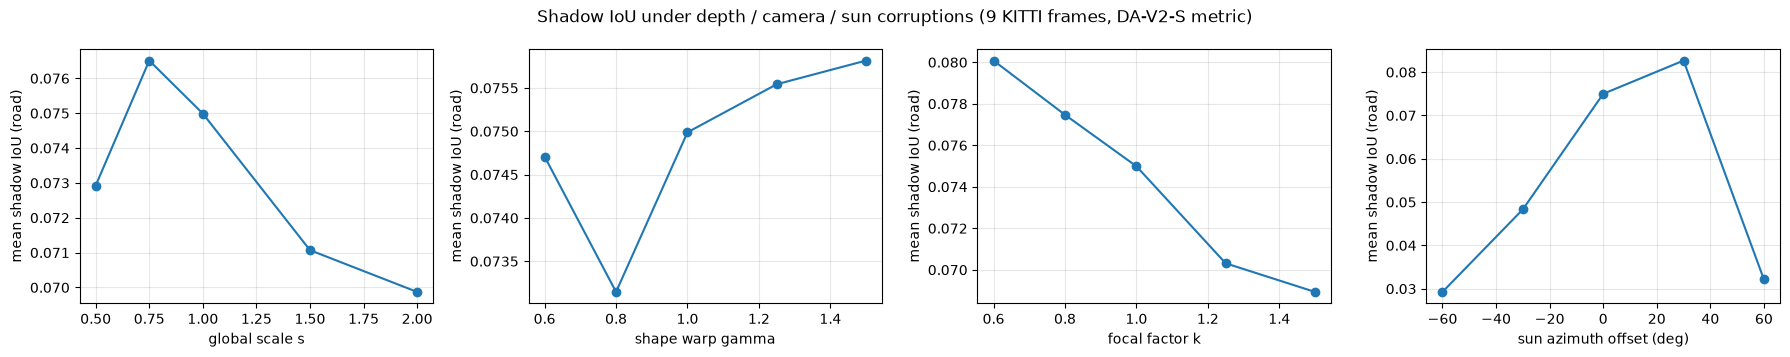

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (name, (xs, ys)) in zip(axes, results.items()):
    ax.plot(xs, ys, "o-")
    ax.set_xlabel(name)
    ax.set_ylabel("mean shadow IoU (road)")
    ax.grid(alpha=0.3)
plt.suptitle(f"Shadow IoU under depth / camera / sun corruptions ({len(data)} KITTI frames, DA-V2-S metric)")
plt.tight_layout()
plt.savefig(FIG / "03_corruption_study.png", dpi=80)
plt.show()